In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

BUCKET_DIR  = 'bucketed_sharpness'
FNO_CKPT    = 'fno_modes64_38traj_seed0.pt'   # saved by FNO.ipynb
CNN_CKPT    = 'cnn_k3_best.pt'                # saved by cnn_full_pipeline.ipynb (one extra line, see below)
RESOLUTIONS = [128, 256, 512]
BUCKETS     = ['smooth', 'medium', 'rough']

# bucket code - roughness based followed by total variation, plots in this file are made based on roughness split

In [ ]:
path = 'data/pdebench_burgers_core.npz'     # the file your bucketing code loads
output_folder = 'bucketed_sharpness'
RESOLUTIONS = [128, 256, 512]
NAMES = ['smooth', 'medium', 'rough']
REF_RES = 512                               # grid the score is measured on (finest = fronts best resolved)

data = np.load(path)
os.makedirs(output_folder, exist_ok=True)


def sharpness(u):
    """RMS slope / RMS of (u - mean u) for each row of u (batch, N), periodic grid on [0, 1)."""
    u = u.astype(np.float64)
    dx = 1.0 / u.shape[1]
    ux = (np.roll(u, -1, axis=1) - np.roll(u, 1, axis=1)) / (2 * dx)
    fluct = u - u.mean(axis=1, keepdims=True)
    return np.sqrt((ux ** 2).mean(axis=1)) / (np.sqrt((fluct ** 2).mean(axis=1)) + 1e-12)


def rel_l2(pred, target):
    return np.linalg.norm(pred - target, axis=1) / (np.linalg.norm(target, axis=1) + 1e-8)


# Rank once on the reference grid; keep each bucket's samples in their original row order
scores = sharpness(data[f'eval_{REF_RES}_field'])
buckets = {name: np.sort(idx) for name, idx in zip(NAMES, np.array_split(np.argsort(scores, kind='stable'), 3))}
labels = np.empty(len(scores), dtype=int)
for k, name in enumerate(NAMES):
    labels[buckets[name]] = k
edges = [(scores[buckets[lo]].max() + scores[buckets[hi]].min()) / 2 for lo, hi in zip(NAMES[:-1], NAMES[1:])]

for res in RESOLUTIONS:
    field, target = data[f'eval_{res}_field'], data[f'eval_{res}_target']
    context, coords = data[f'eval_{res}_context'], data[f'eval_{res}_coordinates']
    assert len(field) == len(scores), f"eval_{res} has a different number of samples than eval_{REF_RES}"
    for name, idx in buckets.items():
        np.savez(f'{output_folder}/eval_{res}_{name}.npz', field=field[idx], target=target[idx],
                 context=context[idx], coordinates=coords, indices=idx, sharpness=scores[idx])
    print(f"Resolution {res} - " + ", ".join(f"{n}: {len(i)}" for n, i in buckets.items()))

np.savez(f'{output_folder}/bucket_info.npz', sharpness=scores, labels=labels, edges=np.array(edges),
         ref_res=REF_RES, **{f'idx_{n}': i for n, i in buckets.items()})

# Check what was written: every bucket file must hold exactly the source rows it claims to
for res in RESOLUTIONS:
    for name in NAMES:
        with np.load(f'{output_folder}/eval_{res}_{name}.npz') as f:
            assert np.array_equal(f['field'], data[f'eval_{res}_field'][f['indices']])
            assert np.array_equal(f['target'], data[f'eval_{res}_target'][f['indices']])
print(f"\nSaved {len(RESOLUTIONS) * len(NAMES)} bucket files and bucket_info.npz to {output_folder}/ (contents verified)")

# Summary: score range, identity error (how much each bucket changes in one step) and the sample numbers
print(f"Sharpness scored at {REF_RES}; bucket edges at R = " + ", ".join(f"{e:.2f}" for e in edges) + "\n")
print(f"{'bucket':<8}{'R range':>17}" + "".join(f"{f'identity @{r}':>15}" for r in RESOLUTIONS))
for name, idx in buckets.items():
    ids = [rel_l2(data[f'eval_{r}_field'][idx], data[f'eval_{r}_target'][idx]).mean() for r in RESOLUTIONS]
    print(f"{name:<8}{f'{scores[idx].min():.2f} - {scores[idx].max():.2f}':>17}" + "".join(f"{v:>15.6f}" for v in ids))
print()
for name, idx in buckets.items():
    print(f"{name:<8} samples: {', '.join(map(str, idx))}")

In [20]:
#TV bucket creation

data = np.load(path)
output_folder = 'TV_buckets'
os.makedirs(output_folder, exist_ok=True)

def process_and_save_eval(res):
    field = data[f'eval_{res}_field'] #takes the eval array of field from 128/256/512
    target = data[f'eval_{res}_target']
    context = data[f'eval_{res}_context']
    coords = data[f'eval_{res}_coordinates']

    roughness_scores = np.mean(np.abs(np.diff(field, axis=1)), axis=1)
    sorted_idx = np.argsort(roughness_scores)  #60 indexes of smooth/medium/rough values
    smooth_idx, medium_idx, rough_idx = np.array_split(sorted_idx, 3) #first 20 indexes-smooth next 20 medium next 20 rough

    print(f"Resolution {res} - Smooth: {len(smooth_idx)}, Medium: {len(medium_idx)}, Rough: {len(rough_idx)}")

    # Using indexes to extract original values then save
    np.savez(f'{output_folder}/eval_{res}_smooth.npz',
             field=field[smooth_idx],
             target=target[smooth_idx],
             context=context[smooth_idx],
             coordinates=coords)

    np.savez(f'{output_folder}/eval_{res}_medium.npz',
             field=field[medium_idx],
             target=target[medium_idx],
             context=context[medium_idx],
             coordinates=coords)

    np.savez(f'{output_folder}/eval_{res}_rough.npz',
             field=field[rough_idx],
             target=target[rough_idx],
             context=context[rough_idx],
             coordinates=coords)

for resolution in [128, 256, 512]:
    process_and_save_eval(resolution)

## made two buckets one based on toughness and other based on TV

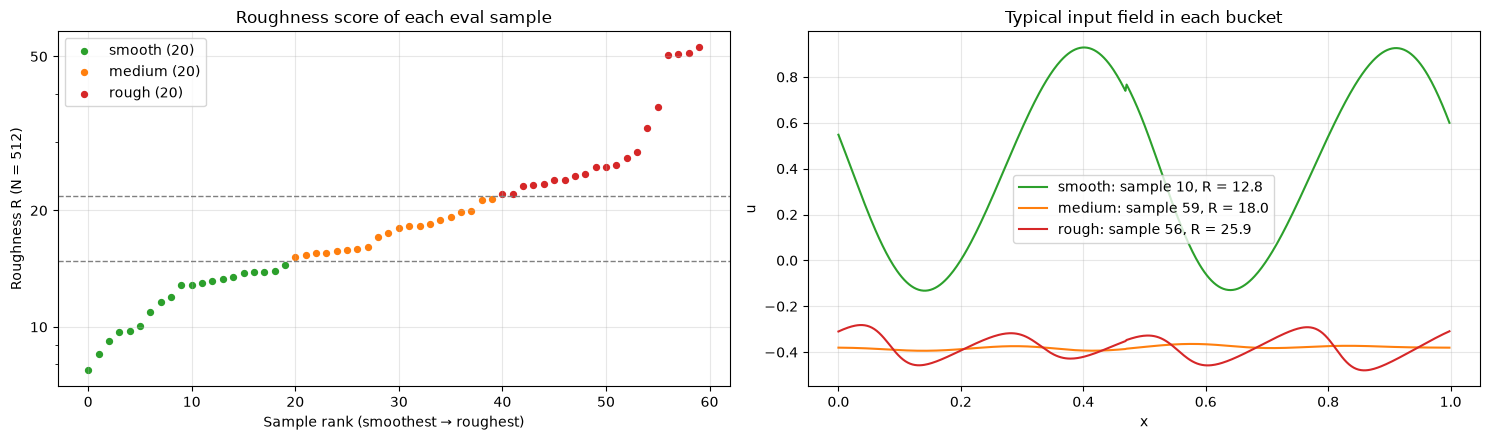

In [16]:
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

BUCKET_COLORS = {'smooth': 'C2', 'medium': 'C1', 'rough': 'C3'}
edges = np.load(f'{BUCKET_DIR}/bucket_info.npz')['edges']      # R values separating the buckets

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# left: every eval sample's roughness score, smoothest to roughest, coloured by bucket
start = 0
for b in BUCKETS:
    r = np.sort(np.load(f'{BUCKET_DIR}/eval_512_{b}.npz')['sharpness'])
    axes[0].scatter(np.arange(start, start + len(r)), r, s=18, color=BUCKET_COLORS[b], label=f'{b} ({len(r)})')
    start += len(r)
for e in edges:
    axes[0].axhline(e, color='gray', ls='--', lw=1)
axes[0].set_yscale('log')
axes[0].yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
axes[0].yaxis.set_minor_formatter(NullFormatter())
axes[0].set_xlabel('Sample rank (smoothest → roughest)')
axes[0].set_ylabel('Roughness R (N = 512)')
axes[0].set_title('Roughness score of each eval sample')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# right: the sample with the middle score in each bucket, on the 512 grid
for b in BUCKETS:
    f = np.load(f'{BUCKET_DIR}/eval_512_{b}.npz')
    k = np.argsort(f['sharpness'])[len(f['sharpness']) // 2]
    x = np.linspace(0, 1, f['field'].shape[1], endpoint=False)
    axes[1].plot(x, f['field'][k], color=BUCKET_COLORS[b],
                 label=f"{b}: sample {f['indices'][k]}, R = {f['sharpness'][k]:.1f}")
axes[1].set_xlabel('x')
axes[1].set_ylabel('u')
axes[1].set_title('Typical input field in each bucket')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## below plots explaining why total variation methods may not be reliable

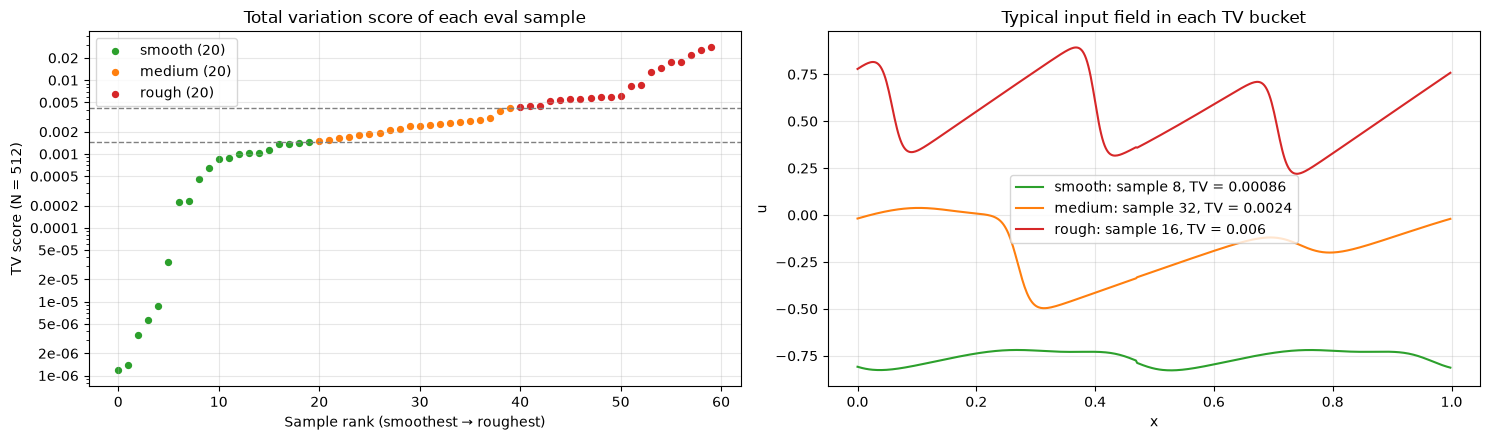

In [17]:
TV_DIR = 'TV_buckets'
BUCKET_COLORS = {'smooth': 'C2', 'medium': 'C1', 'rough': 'C3'}

def tv_score(u):
    """Total variation per grid step, the score the TV buckets were ranked by: mean |u[i+1] - u[i]|."""
    return np.mean(np.abs(np.diff(u, axis=1)), axis=1)

# The TV files don't store scores or sample numbers, so work them out from the fields:
# score each sample, and find its row in the original eval set
all_fields = np.load('data/pdebench_burgers_core.npz')['eval_512_field']
tv = {}
for b in BUCKETS:
    field = np.load(f'{TV_DIR}/eval_512_{b}.npz')['field']
    index = [int(np.flatnonzero((all_fields == row).all(axis=1))[0]) for row in field]
    tv[b] = dict(field=field, score=tv_score(field), index=index)
edges = [(tv[lo]['score'].max() + tv[hi]['score'].min()) / 2 for lo, hi in zip(BUCKETS[:-1], BUCKETS[1:])]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# left: every eval sample's TV score, smoothest to roughest, coloured by bucket
start = 0
for b in BUCKETS:
    s = np.sort(tv[b]['score'])
    axes[0].scatter(np.arange(start, start + len(s)), s, s=18, color=BUCKET_COLORS[b], label=f'{b} ({len(s)})')
    start += len(s)
for e in edges:
    axes[0].axhline(e, color='gray', ls='--', lw=1)
axes[0].set_yscale('log')
axes[0].yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
axes[0].yaxis.set_minor_formatter(NullFormatter())
axes[0].set_xlabel('Sample rank (smoothest → roughest)')
axes[0].set_ylabel('TV score (N = 512)')
axes[0].set_title('Total variation score of each eval sample')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# right: the sample with the middle score in each bucket, on the 512 grid
for b in BUCKETS:
    k = np.argsort(tv[b]['score'])[len(tv[b]['score']) // 2]
    x = np.linspace(0, 1, tv[b]['field'].shape[1], endpoint=False)
    axes[1].plot(x, tv[b]['field'][k], color=BUCKET_COLORS[b],
                 label=f"{b}: sample {tv[b]['index'][k]}, TV = {tv[b]['score'][k]:.2g}")
axes[1].set_xlabel('x')
axes[1].set_ylabel('u')
axes[1].set_title('Typical input field in each TV bucket')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## two model classes

In [2]:
def make_input(u):
    """(batch, N) -> (batch, N, 2): the value u and its position x in [0, 1)."""
    batch, n_points = u.shape
    x = torch.linspace(0, 1, n_points + 1, device=u.device)[:-1]
    x = x.expand(batch, n_points)
    return torch.stack([u, x], dim=-1)


class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):
        batch, _, n_points = x.shape
        x_freq = torch.fft.rfft(x)
        out_freq = torch.zeros(batch, self.weights.shape[1], n_points // 2 + 1,
                               dtype=torch.cfloat, device=x.device)
        k = min(self.modes, n_points // 2 + 1)
        out_freq[:, :, :k] = torch.einsum("bix,iox->box", x_freq[:, :, :k], self.weights[:, :, :k])
        return torch.fft.irfft(out_freq, n=n_points)


class FNO1d(nn.Module):
    def __init__(self, modes=64, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.w    = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))

    def forward(self, x):
        x = self.lift(x).permute(0, 2, 1)
        for fourier, local in zip(self.spec, self.w):
            x = nn.functional.gelu(fourier(x) + local(x))
        x = x.permute(0, 2, 1)
        return self.proj(x).squeeze(-1)


class GridLockedCNN(nn.Module):
    def __init__(self, hidden=64, kernel_size=3, num_layers=4):
        super().__init__()
        layers = [nn.Conv1d(1, hidden, kernel_size, padding=kernel_size // 2,
                            padding_mode='circular'), nn.ReLU()]
        for _ in range(num_layers - 1):
            layers += [nn.Conv1d(hidden, hidden, kernel_size, padding=kernel_size // 2,
                                 padding_mode='circular'), nn.ReLU()]
        layers.append(nn.Conv1d(hidden, 1, kernel_size, padding=kernel_size // 2,
                                padding_mode='circular'))
        self.net = nn.Sequential(*layers)

    def forward(self, u):
        return u + self.net(u)

## loading the trained weights

In [3]:
ckpt = torch.load(FNO_CKPT, map_location='cpu', weights_only=False)
fno = FNO1d(**ckpt['config'])
fno.load_state_dict(ckpt['state'])
fno.eval()

ckpt = torch.load(CNN_CKPT, map_location='cpu', weights_only=False)
cnn = GridLockedCNN(**ckpt['config'])
cnn.load_state_dict(ckpt['state'])
cnn.eval()

print('both models loaded')

both models loaded


## Each model makes a prediction and return u-next in desired shape

In [4]:
def predict_fno(u_now):
    with torch.no_grad():
        u = torch.tensor(u_now, dtype=torch.float32)
        return fno(make_input(u)).numpy()                 # (samples, N, 2) in -> (samples, N) out


def predict_cnn(u_now):
    with torch.no_grad():
        u = torch.tensor(u_now, dtype=torch.float32)
        return cnn(u[:, None, :])[:, 0, :].numpy()        # (samples, 1, N) in -> (samples, N) out

## Scoring the pred

In [5]:
def rel_l2(pred, true):
    mistake = np.linalg.norm(pred - true, axis=1)
    size    = np.linalg.norm(true, axis=1) + 1e-8
    return mistake / size

## Running both models on every bucket

For each of the 9 bucket files: load it, predict with both models, score each prediction against the true u_next.

In [6]:
err  = {m: {b: {} for b in BUCKETS} for m in ['FNO', 'CNN', 'Identity']}
pred = {m: {b: {} for b in BUCKETS} for m in ['FNO', 'CNN']}
data = {b: {} for b in BUCKETS}                       # keep inputs/answers for the example plot

for b in BUCKETS:
    for res in RESOLUTIONS:
        f = np.load(f'{BUCKET_DIR}/eval_{res}_{b}.npz')
        u_now, u_next = f['field'], f['target']        # (20, res) each
        data[b][res] = dict(u_now=u_now, u_next=u_next, sharpness=f['sharpness'])

        pred['FNO'][b][res] = predict_fno(u_now)
        pred['CNN'][b][res] = predict_cnn(u_now)

        err['FNO'][b][res]      = rel_l2(pred['FNO'][b][res], u_next)
        err['CNN'][b][res]      = rel_l2(pred['CNN'][b][res], u_next)
        err['Identity'][b][res] = rel_l2(u_now, u_next)

        print(f"{b:<7}{res:>4} pts, {len(u_now)} samples   "
              f"FNO {err['FNO'][b][res].mean():.5f}   CNN {err['CNN'][b][res].mean():.5f}")

smooth  128 pts, 20 samples   FNO 0.00119   CNN 0.00062
smooth  256 pts, 20 samples   FNO 0.00216   CNN 0.00698
smooth  512 pts, 20 samples   FNO 0.00239   CNN 0.01014
medium  128 pts, 20 samples   FNO 0.00143   CNN 0.00109
medium  256 pts, 20 samples   FNO 0.00243   CNN 0.01202
medium  512 pts, 20 samples   FNO 0.00271   CNN 0.01739
rough   128 pts, 20 samples   FNO 0.00782   CNN 0.00661
rough   256 pts, 20 samples   FNO 0.00838   CNN 0.03300
rough   512 pts, 20 samples   FNO 0.00855   CNN 0.04770


In [7]:
# Check: averaged over all 60 samples this should match the model notebooks
# (FNO 0.003480 / 0.004325 / 0.004549,  CNN 0.002776 / 0.017335 / 0.025076)
for m in ['FNO', 'CNN']:
    overall = [np.concatenate([err[m][b][r] for b in BUCKETS]).mean() for r in RESOLUTIONS]
    print(m, '  '.join(f'{v:.6f}' for v in overall))

FNO 0.003480  0.004325  0.004549
CNN 0.002776  0.017335  0.025076


## Step 6: results table

Mean error over each bucket's 20 samples. `growth` = error at 512 / error at 128: 1.0 means the model works just as well on the finer grid.

In [8]:
print(f"{'model':<10}{'bucket':<8}" + ''.join(f'{r:>10}' for r in RESOLUTIONS) + f"{'growth':>10}")
for m in ['FNO', 'CNN', 'Identity']:
    for b in BUCKETS:
        means = [err[m][b][r].mean() for r in RESOLUTIONS]
        print(f'{m:<10}{b:<8}' + ''.join(f'{v:>10.5f}' for v in means) + f'{means[-1] / means[0]:>9.2f}x')
    print()

print('Samples (out of 20) where the FNO is closer to u_next than the CNN')
for b in BUCKETS:
    wins = [int(np.sum(err['FNO'][b][r] < err['CNN'][b][r])) for r in RESOLUTIONS]
    print(f'{b:<8}' + '   '.join(f'{r} pts: {w}/20' for r, w in zip(RESOLUTIONS, wins)))

model     bucket         128       256       512    growth
FNO       smooth     0.00119   0.00216   0.00239     2.01x
FNO       medium     0.00143   0.00243   0.00271     1.89x
FNO       rough      0.00782   0.00838   0.00855     1.09x

CNN       smooth     0.00062   0.00698   0.01014    16.22x
CNN       medium     0.00109   0.01202   0.01739    15.89x
CNN       rough      0.00661   0.03300   0.04770     7.22x

Identity  smooth     0.01318   0.01318   0.01318     1.00x
Identity  medium     0.02252   0.02252   0.02252     1.00x
Identity  rough      0.06190   0.06194   0.06196     1.00x

Samples (out of 20) where the FNO is closer to u_next than the CNN
smooth  128 pts: 2/20   256 pts: 15/20   512 pts: 15/20
medium  128 pts: 7/20   256 pts: 19/20   512 pts: 19/20
rough   128 pts: 10/20   256 pts: 17/20   512 pts: 17/20


## Step 7: plots

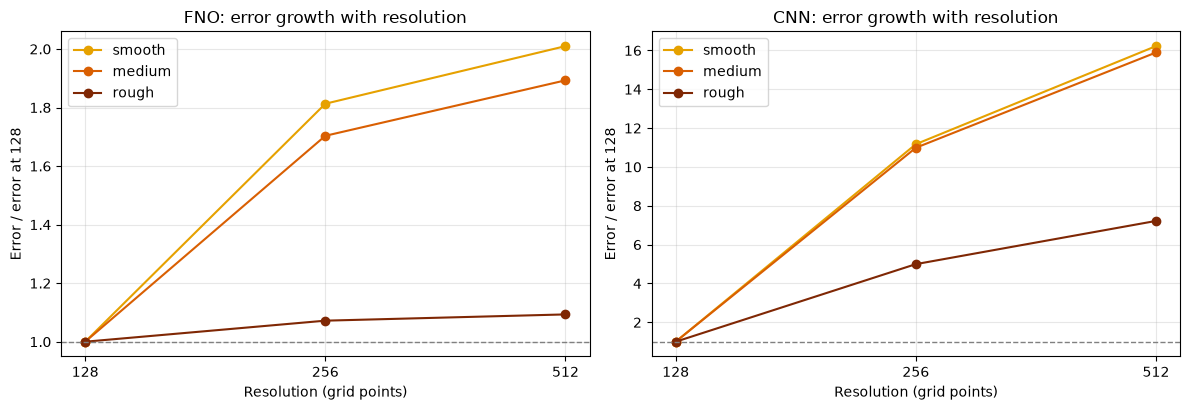

In [10]:
# Plot B: how each bucket's error changes as the grid gets finer (1.0 = no change from 128)
BUCKET_COLORS = {'smooth': '#e6a100', 'medium': '#d95f02', 'rough': '#7f2704'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, m in zip(axes, ['FNO', 'CNN']):
    for b in BUCKETS:
        growth = [err[m][b][r].mean() / err[m][b][128].mean() for r in RESOLUTIONS]
        ax.plot(RESOLUTIONS, growth, 'o-', color=BUCKET_COLORS[b], label=b)
    ax.axhline(1, color='gray', ls='--', lw=1)
    ax.set_xscale('log', base=2)
    ax.set_xticks(RESOLUTIONS)
    ax.set_xticklabels([str(r) for r in RESOLUTIONS])
    ax.minorticks_off()
    ax.set_xlabel('Resolution (grid points)')
    ax.set_ylabel('Error / error at 128')
    ax.set_title(f'{m}: error growth with resolution')
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

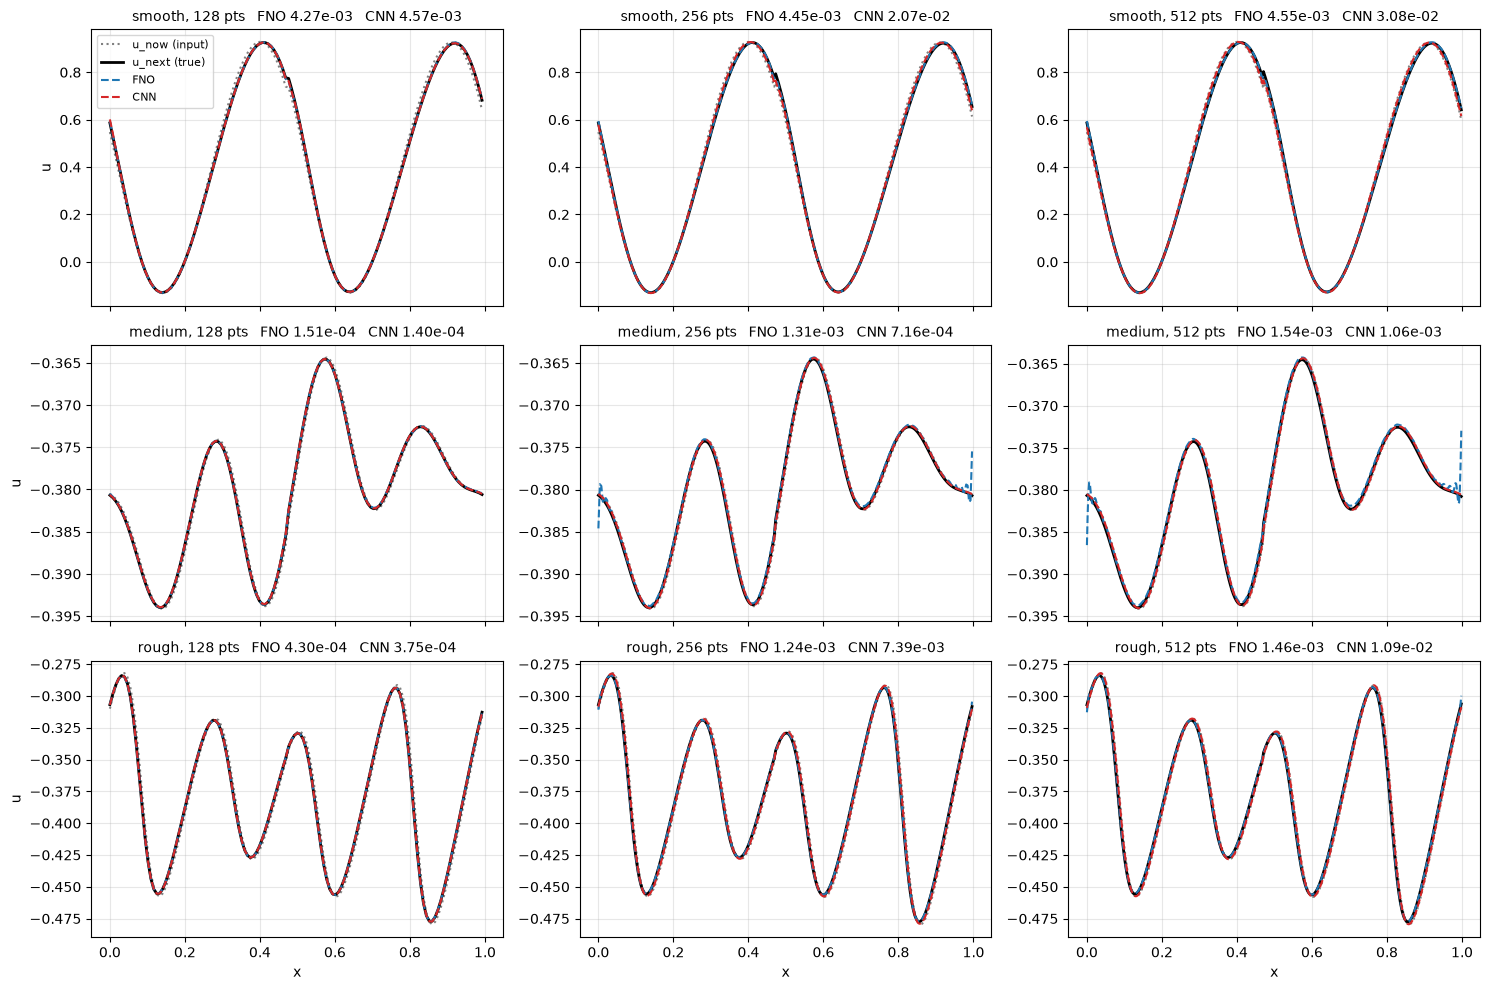

In [11]:
# Plot C: one typical sample per bucket (the one with the middle sharpness), at all three resolutions
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for i, b in enumerate(BUCKETS):
    s = np.argsort(data[b][512]['sharpness'])[10]          # same sample at every resolution
    for j, res in enumerate(RESOLUTIONS):
        ax = axes[i, j]
        xg = np.linspace(0, 1, res, endpoint=False)
        ax.plot(xg, data[b][res]['u_now'][s],  ':',  color='gray', label='u_now (input)')
        ax.plot(xg, data[b][res]['u_next'][s], '-',  color='k', lw=2, label='u_next (true)')
        ax.plot(xg, pred['FNO'][b][res][s],    '--', color=COLORS['FNO'], label='FNO')
        ax.plot(xg, pred['CNN'][b][res][s],    '--', color=COLORS['CNN'], label='CNN')
        ax.set_title(f"{b}, {res} pts   FNO {err['FNO'][b][res][s]:.2e}   CNN {err['CNN'][b][res][s]:.2e}",
                     fontsize=10)
        ax.grid(True, alpha=0.3)
    axes[i, 0].set_ylabel('u')
for ax in axes[-1]:
    ax.set_xlabel('x')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## keeping x axis as u_next to see actual variaation

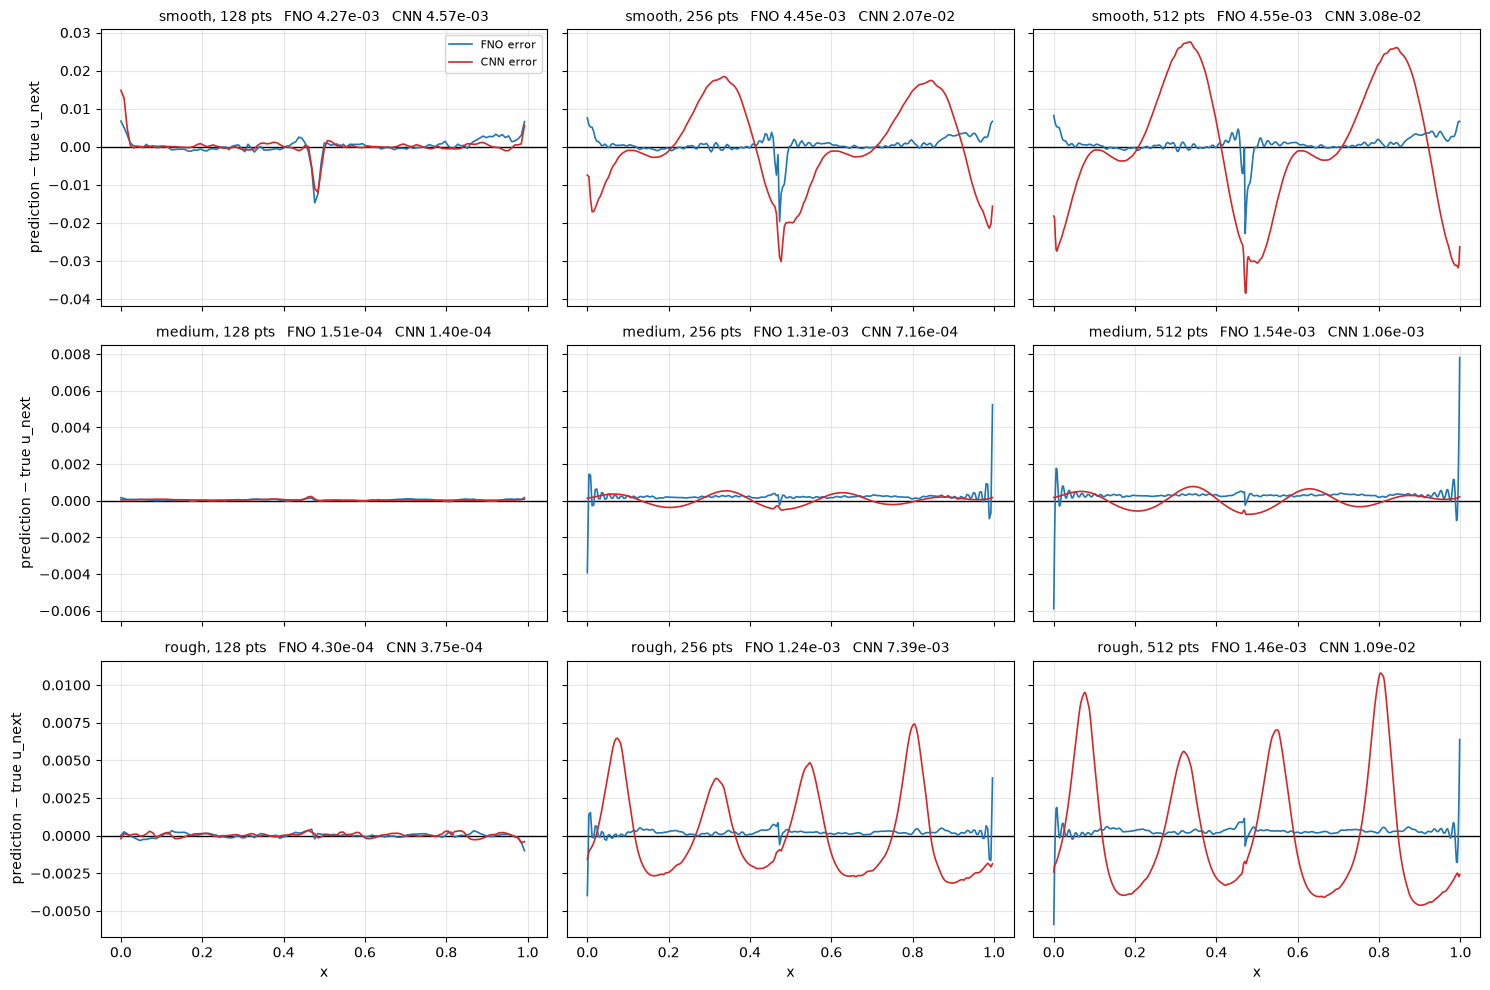

In [15]:
# the same samples, but showing each model's error (prediction - true u_next) instead of the fields
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True, sharey='row')
for i, b in enumerate(BUCKETS):
    sharp = data[b][512]['sharpness']
    s = np.argsort(sharp)[10] if sharp is not None else 10      # same sample as Plot C
    for j, res in enumerate(RESOLUTIONS):
        ax = axes[i, j]
        xg = np.linspace(0, 1, res, endpoint=False)
        u_next = data[b][res]['u_next'][s]
        ax.axhline(0, color='k', lw=1)
        ax.plot(xg, pred['FNO'][b][res][s] - u_next, color=COLORS['FNO'], lw=1.2, label='FNO error')
        ax.plot(xg, pred['CNN'][b][res][s] - u_next, color=COLORS['CNN'], lw=1.2, label='CNN error')
        ax.set_title(f"{b}, {res} pts   FNO {err['FNO'][b][res][s]:.2e}   CNN {err['CNN'][b][res][s]:.2e}",
                     fontsize=10)
        ax.grid(True, alpha=0.3)
    axes[i, 0].set_ylabel('prediction − true u_next')
for ax in axes[-1]:
    ax.set_xlabel('x')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

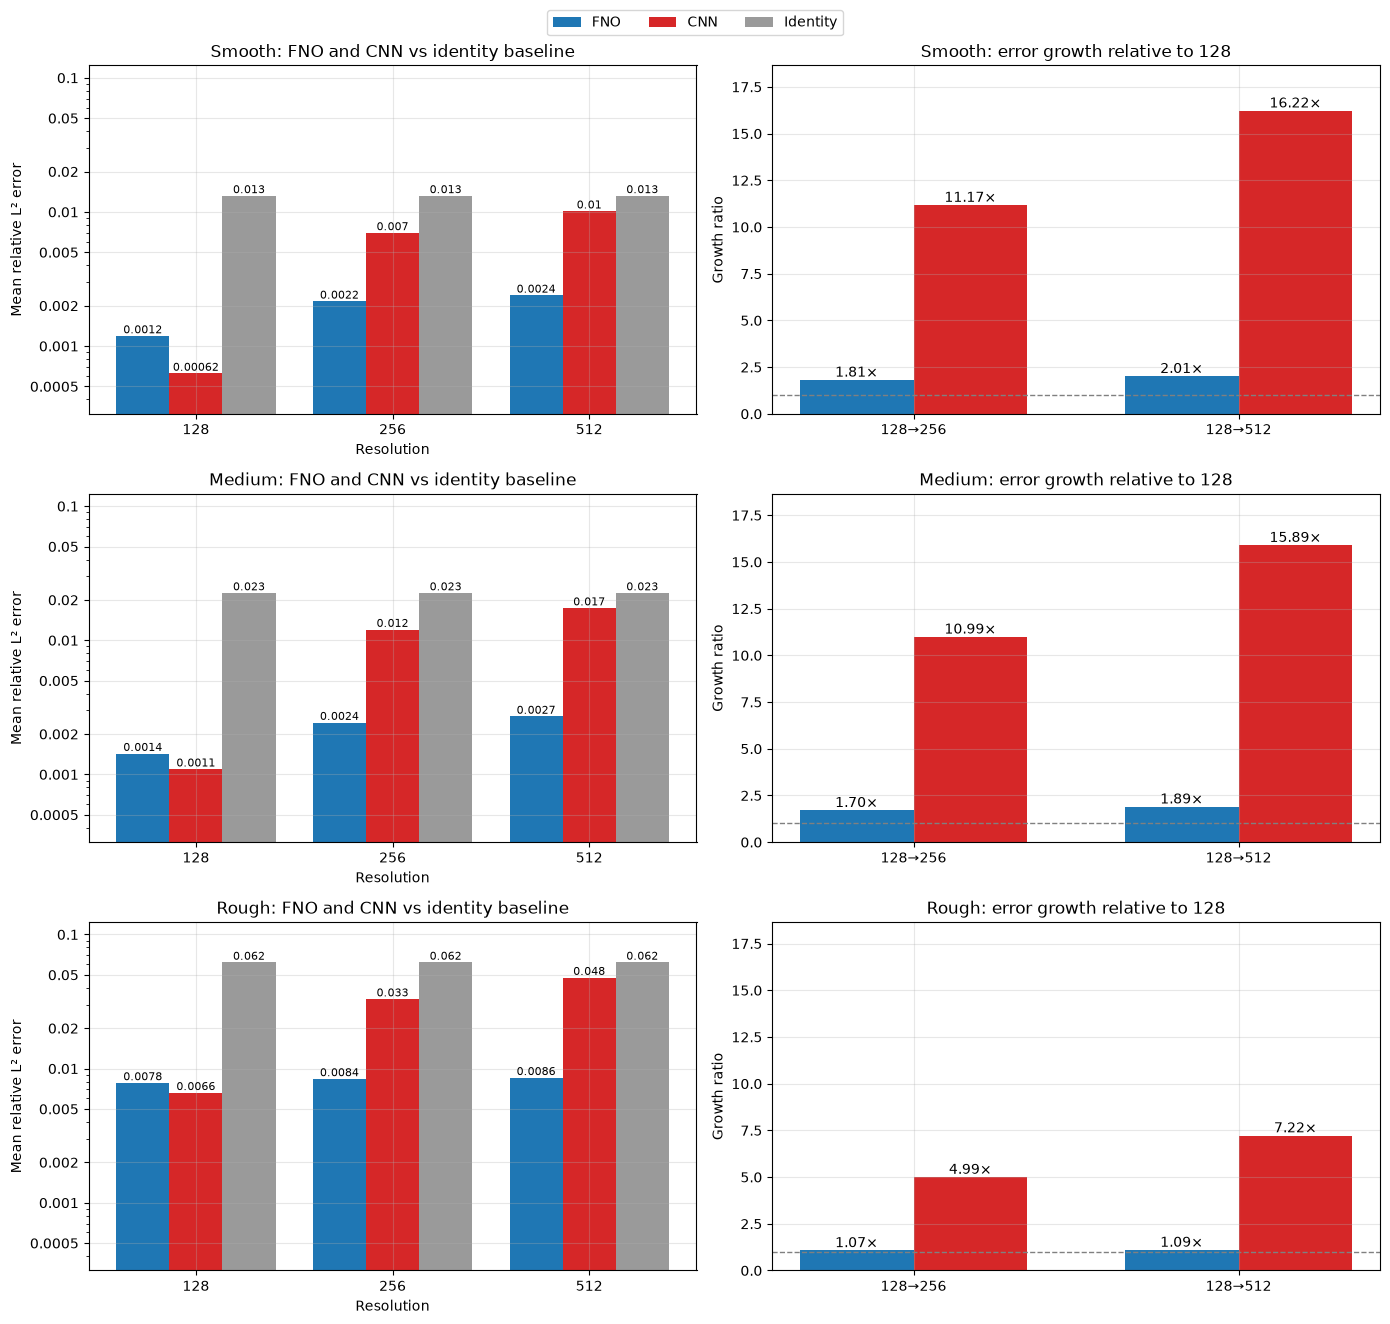

In [14]:
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

COLORS = {'FNO': '#1f77b4', 'CNN': '#d62728', 'Identity': '#9a9a9a'}

growth = {m: {b: [err[m][b][r].mean() / err[m][b][128].mean() for r in RESOLUTIONS[1:]] for b in BUCKETS}
          for m in ['FNO', 'CNN']}
all_means = [err[m][b][r].mean() for m in ['FNO', 'CNN', 'Identity'] for b in BUCKETS for r in RESOLUTIONS]

fig, axes = plt.subplots(len(BUCKETS), 2, figsize=(14, 13))
for row, b in enumerate(BUCKETS):
    # left: mean error at each resolution
    ax = axes[row, 0]
    x, w = np.arange(len(RESOLUTIONS)), 0.27
    for k, m in enumerate(['FNO', 'CNN', 'Identity']):
        xs = x + (k - 1) * w
        means = [err[m][b][r].mean() for r in RESOLUTIONS]
        ax.bar(xs, means, w, color=COLORS[m], label=m)
        for xi, v in zip(xs, means):
            ax.text(xi, v, f'{v:.2g}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([str(r) for r in RESOLUTIONS])
    ax.set_xlabel('Resolution')
    ax.set_ylabel('Mean relative L² error')
    ax.set_yscale('log')
    ax.set_ylim(min(all_means) * 0.5, max(all_means) * 2)
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_title(f'{b.capitalize()}: FNO and CNN vs identity baseline')
    ax.grid(True, alpha=0.3)

    # right: error at 256 and 512 divided by error at 128
    ax = axes[row, 1]
    x, w = np.arange(len(RESOLUTIONS) - 1), 0.35
    for k, m in enumerate(['FNO', 'CNN']):
        xs = x + (k - 0.5) * w
        ax.bar(xs, growth[m][b], w, color=COLORS[m])
        for xi, v in zip(xs, growth[m][b]):
            ax.text(xi, v, f'{v:.2f}×', ha='center', va='bottom')
    ax.axhline(1, color='gray', ls='--', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f'128→{r}' for r in RESOLUTIONS[1:]])
    ax.set_ylabel('Growth ratio')
    ax.set_ylim(0, max(max(g) for m in growth for g in growth[m].values()) * 1.15)
    ax.set_title(f'{b.capitalize()}: error growth relative to 128')
    ax.grid(True, alpha=0.3)

fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

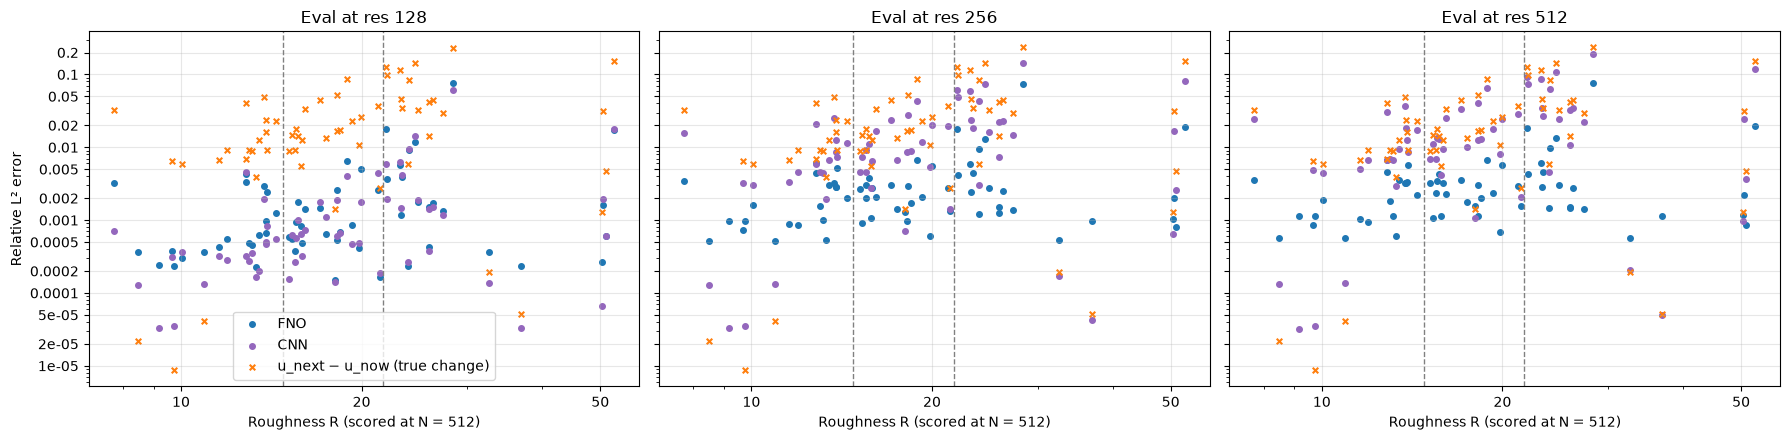

In [19]:
score  = {b: data[b][512]['sharpness'] for b in BUCKETS}
XLABEL = 'Roughness R (scored at N = 512)'
# for the TV buckets use these two lines instead:
# score  = {b: np.mean(np.abs(np.diff(data[b][512]['u_now'], axis=1)), axis=1) for b in BUCKETS}
# XLABEL = 'TV score (N = 512)'

STYLE = {'FNO':      dict(color='C0', marker='o', label='FNO'),
         'CNN':      dict(color='C4', marker='o', label='CNN'),
         'Identity': dict(color='C1', marker='x', label='u_next − u_now (true change)')}
edges = [(score[lo].max() + score[hi].min()) / 2 for lo, hi in zip(BUCKETS[:-1], BUCKETS[1:])]
x_all = np.concatenate([score[b] for b in BUCKETS])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, res in zip(axes, RESOLUTIONS):
    for m in ['FNO', 'CNN', 'Identity']:
        y_all = np.concatenate([err[m][b][res] for b in BUCKETS])
        ax.scatter(x_all, y_all, s=16, **STYLE[m])
    for e in edges:
        ax.axvline(e, color='gray', ls='--', lw=1)
    ax.set_xscale('log')
    ax.set_yscale('log')
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
        axis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
        axis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(XLABEL)
    ax.set_title(f'Eval at res {res}')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('Relative L² error')
axes[0].legend()
plt.tight_layout()
plt.show()